In [1]:
!pip install -q xgboost shap

In [2]:
# import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("XGBoost version:", xgb.__version__)
print("SHAP version:", shap.__version__)

XGBoost version: 3.4.1
SHAP version: 0.54.1


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path
import os

PROJECT_DIR = Path(os.environ.get("RETAIL_PROJECT_DIR", Path.cwd())).resolve()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = next(
        (parent for parent in PROJECT_DIR.parents if (parent / "data").is_dir()),
        Path("/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction")
    )
DATA_DIR = PROJECT_DIR / "data"

file_path = DATA_DIR / "online_retail.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (525461, 8)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


In [6]:
# Check data quality and date range

import pandas as pd
import numpy as np

# Convert columns to appropriate data types
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

df["Customer ID"] = pd.to_numeric(
    df["Customer ID"],
    errors="coerce"
)

df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
)

df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

# Basic inspection
print("Dataset shape:", df.shape)
print("\nDate range:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nUnique customers:", df["Customer ID"].nunique())
print("Unique invoices:", df["Invoice"].nunique())
print("Duplicate rows:", df.duplicated().sum())

print("\nQuantity summary:")
display(df["Quantity"].describe())

print("\nPrice summary:")
display(df["Price"].describe())

Dataset shape: (525461, 8)

Date range:
Start: 2009-12-01 07:45:00
End: 2010-12-09 20:01:00

Missing values:


,Missing Values
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0



Unique customers: 4383
Unique invoices: 28816
Duplicate rows: 6865

Quantity summary:


,Quantity
count,525461.000000
mean,10.337667
std,107.424110
min,-9600.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,19152.000000



Price summary:


,Price
count,525461.000000
mean,4.688834
std,146.126914
min,-53594.360000
25%,1.250000
50%,2.100000
75%,4.210000
max,25111.090000


In [7]:
# Clean the transaction data

# Work on a separate copy
retail = df.copy()

# Remove rows without customer or date information
retail = retail.dropna(
    subset=["Customer ID", "InvoiceDate"]
).copy()

# Remove exact duplicate transactions
retail = retail.drop_duplicates().copy()

# Identify cancelled invoices
retail["Invoice"] = retail["Invoice"].astype(str)
retail["IsCancelled"] = retail["Invoice"].str.startswith("C")

# Revenue for transaction analysis
retail["Revenue"] = retail["Quantity"] * retail["Price"]

print("Rows after basic cleaning:", retail.shape)
print("Unique customers:", retail["Customer ID"].nunique())
print("Cancelled invoice rows:", retail["IsCancelled"].sum())

Rows after basic cleaning: (410763, 10)
Unique customers: 4383
Cancelled invoice rows: 9816


In [8]:
import os

# Get the parent directory of the current file_path
folder_path = os.path.dirname(file_path)

# Create the folder if it doesn't exist
os.makedirs(folder_path, exist_ok=True)

# Save the cleaned dataset in the same folder
export_path = os.path.join(folder_path, "retail_cleaned.csv")
retail.to_csv(export_path, index=False)

print("Cleaned dataset saved successfully!")
print("File location:", export_path)
print("Dataset shape:", retail.shape)

Cleaned dataset saved successfully!
File location: /content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction/retail_cleaned.csv
Dataset shape: (410763, 10)


In [9]:
# Only use non-cancelled, positive-quantity purchases
purchases = retail.loc[
    (~retail["IsCancelled"])
    & (retail["Quantity"] > 0)
    & (retail["Price"] > 0)
].copy()

last_date = purchases["InvoiceDate"].max()

# Latest possible cutoff with a complete 90-day outcome window
cutoff_date = last_date - pd.Timedelta(days=90)

print("Last qualifying purchase date:", last_date)
print("Candidate cutoff date:", cutoff_date)
print("Outcome window ends:", cutoff_date + pd.Timedelta(days=90))

Last qualifying purchase date: 2010-12-09 20:01:00
Candidate cutoff date: 2010-09-10 20:01:00
Outcome window ends: 2010-12-09 20:01:00


In [10]:
# Build customer-level features and the target

# Observation period
history = purchases[
    purchases["InvoiceDate"] < cutoff_date
].copy()

# Outcome period: cutoff inclusive, next 90 days
outcome_end = cutoff_date + pd.Timedelta(days=90)

future = purchases[
    (purchases["InvoiceDate"] >= cutoff_date)
    & (purchases["InvoiceDate"] < outcome_end)
].copy()

# Customer features using historical data only
customer_features = history.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique"),
    Country=("Country", "last")
).reset_index()

customer_features["Recency"] = (
    cutoff_date - customer_features["LastPurchase"]
).dt.days

customer_features["AvgOrderValue"] = (
    customer_features["Monetary"]
    / customer_features["Frequency"].replace(0, np.nan)
)

# Customer purchases in the future outcome window
future_customers = set(future["Customer ID"].unique())

customer_features["Churn"] = (
    ~customer_features["Customer ID"].isin(future_customers)
).astype(int)

# Remove timestamp feature after calculating recency
customer_features = customer_features.drop(
    columns=["LastPurchase"]
)

print("Customer-level dataset:", customer_features.shape)
print("\nChurn distribution:")
display(
    customer_features["Churn"]
    .value_counts()
    .rename(index={0: "Active", 1: "Churned"})
    .to_frame("Customers")
)

display(customer_features.head())

Customer-level dataset: (3377, 9)

Churn distribution:


,Customers
Churn,
Active,1941
Churned,1436


,Customer ID,Frequency,Monetary,TotalQuantity,UniqueProducts,Country,Recency,AvgOrderValue,Churn
0,12346.0,11,372.86,70,26,United Kingdom,74,33.896364,1
1,12349.0,2,1268.52,474,47,Italy,115,634.260000,0
2,12355.0,1,488.21,303,22,Bahrain,112,488.210000,1
3,12358.0,2,1697.93,590,34,Austria,95,848.965000,0
4,12359.0,5,2012.03,877,82,Cyprus,80,402.406000,0


In [11]:
# Verify the target before training

print("Target missing values:", customer_features["Churn"].isna().sum())

print("\nChurn percentage:")
display(
    (customer_features["Churn"].value_counts(normalize=True) * 100)
    .rename(index={0: "Active", 1: "Churned"})
    .round(2)
    .to_frame("Percentage")
)

print("\nFeature data types:")
display(customer_features.dtypes.to_frame("Data Type"))

Target missing values: 0

Churn percentage:


,Percentage
Churn,
Active,57.48
Churned,42.52



Feature data types:


,Data Type
Customer ID,float64
Frequency,int64
Monetary,float64
TotalQuantity,int64
UniqueProducts,int64
Country,object
Recency,int64
AvgOrderValue,float64
Churn,int64


In [12]:
# Prepare the feature matrix

# Separate features and target
X = customer_features.drop(
    columns=["Churn", "Customer ID"]
)

y = customer_features["Churn"].astype(int)

# Encode Country as a numeric feature
X = pd.get_dummies(
    X,
    columns=["Country"],
    drop_first=False,
    dtype=int
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))
print("\nMissing feature values:", X.isnull().sum().sum())

Feature matrix shape: (3377, 39)
Target shape: (3377,)

Target distribution:
Churn
0    57.48
1    42.52
Name: proportion, dtype: float64

Missing feature values: 0


In [13]:
# train/test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

Training features: (2701, 39)
Testing features: (676, 39)

Training churn distribution:
Churn
0    57.46
1    42.54
Name: proportion, dtype: float64


In [14]:
# train the XGBoost model

%pip install -q xgboost shap

In [15]:
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Initialize the model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
y_pred = xgb_model.predict(X_test)
y_prob = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Active", "Churned"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6524
ROC-AUC: 0.7101

Classification Report:
              precision    recall  f1-score   support

      Active       0.70      0.69      0.69       389
     Churned       0.59      0.61      0.60       287

    accuracy                           0.65       676
   macro avg       0.65      0.65      0.65       676
weighted avg       0.65      0.65      0.65       676


Confusion Matrix:
[[267 122]
 [113 174]]


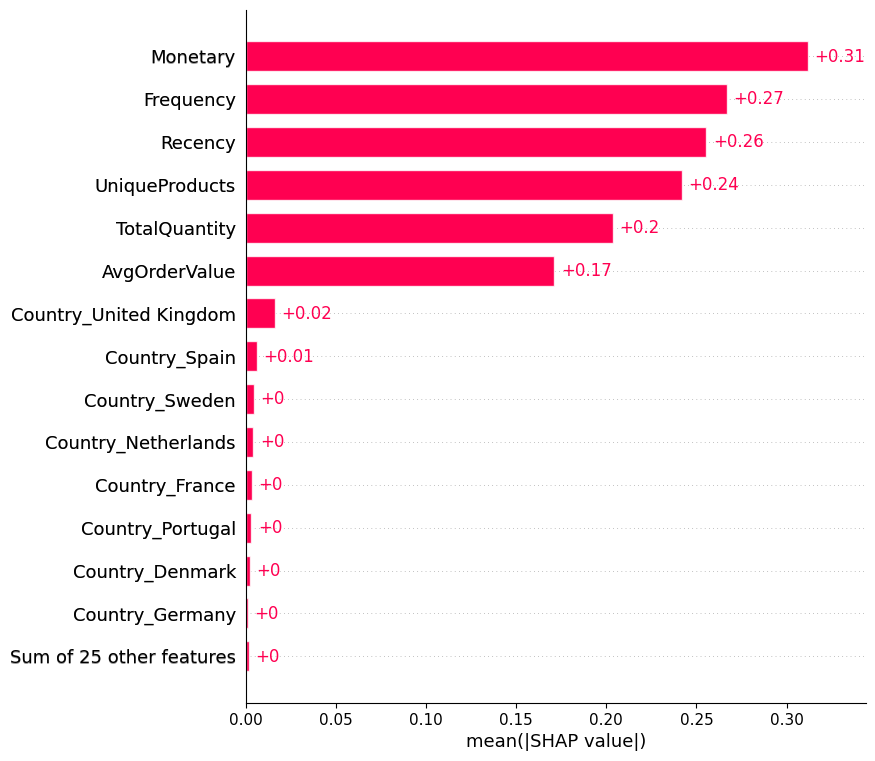

In [16]:
# SHAP explainability

import shap

# Create SHAP explainer for the trained XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for test data
shap_values = explainer(X_test)

# Global feature importance
shap.plots.bar(shap_values, max_display=15)

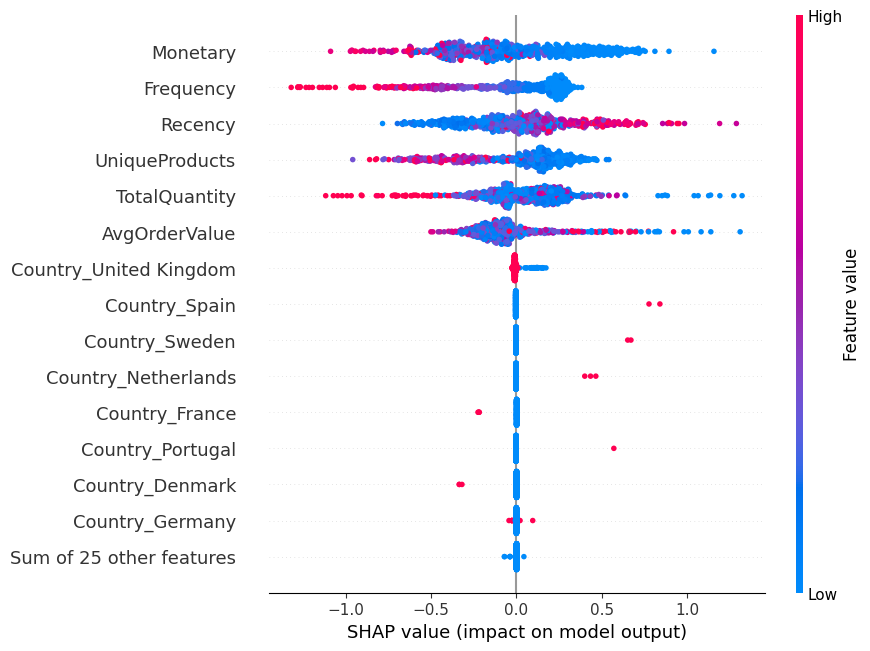

In [17]:
# Understand how each feature affects churn

# Summary plot showing positive and negative feature impacts
shap.plots.beeswarm(shap_values, max_display=15)

**Key observations of plot**

- Monetary: High and low values appear on both sides of zero. Spending does not show a simple, consistent relationship with churn in this model.
- Frequency: Many high-value observations (pink) appear on the negative side, while lower-value observations (blue) cluster closer to the positive side. This suggests more frequent purchasing often pushes predictions toward Active.
- Recency: Higher values (pink) tend to appear on the positive side, suggesting that customers who have gone longer since their last purchase are more likely to be predicted as Churned.
- UniqueProducts: Many high values appear on the negative side, suggesting customers buying a wider variety of products may be more likely to be predicted as Active.
- TotalQuantity and AvgOrderValue: Their contributions vary across customers, so the relationship is not straightforward.
- Country: Most observations have SHAP values close to zero, indicating relatively small contributions overall.

**SHAP-Based Model Explainability**

SHAP (SHapley Additive exPlanations) was used to interpret the XGBoost churn prediction model. The global feature importance plot identified Monetary, Frequency, Recency, UniqueProducts, TotalQuantity, and AvgOrderValue as the most influential features.

The SHAP summary plot indicated that Recency generally pushes predictions toward churn when its values are high, whereas higher Frequency often pushes predictions toward the active class. This is consistent with the expectation that customers who purchase less frequently or have not purchased recently may be at greater risk of churn.

Country-related features had comparatively low overall importance. Monetary and other purchasing behavior features showed varying effects across customers, indicating that churn predictions depend on combinations of customer characteristics rather than one feature alone.

The analysis provides interpretable insights that can help prioritize customer retention strategies. SHAP explains the model's predictions and should not be interpreted as evidence of causal relationships.

**Important validation before finalizing**

Your XGBoost model achieved 65.24% accuracy and 0.7101 ROC-AUC, with 61% recall for churned customers. SHAP explains these predictions but does not itself improve the model.

One additional check is particularly important: ensure that Monetary, Frequency, Recency, and the other features were calculated strictly from purchases before the churn prediction cutoff. If they include purchases from the future outcome window, the evaluation may be affected by data leakage.

In [18]:
# Save the trained XGBoost model

import os
import joblib

# Create a folder in Google Drive
model_dir = str(PROJECT_DIR / "churn_model")
os.makedirs(model_dir, exist_ok=True)

# Save trained model
model_path = os.path.join(model_dir, "xgboost_churn_model.pkl")
joblib.dump(xgb_model, model_path)

# Save feature column names and order
feature_path = os.path.join(model_dir, "feature_columns.pkl")
joblib.dump(X_train.columns.tolist(), feature_path)

print("Model saved:", model_path)
print("Feature columns saved:", feature_path)

Model saved: /content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction/churn_model/xgboost_churn_model.pkl
Feature columns saved: /content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction/churn_model/feature_columns.pkl


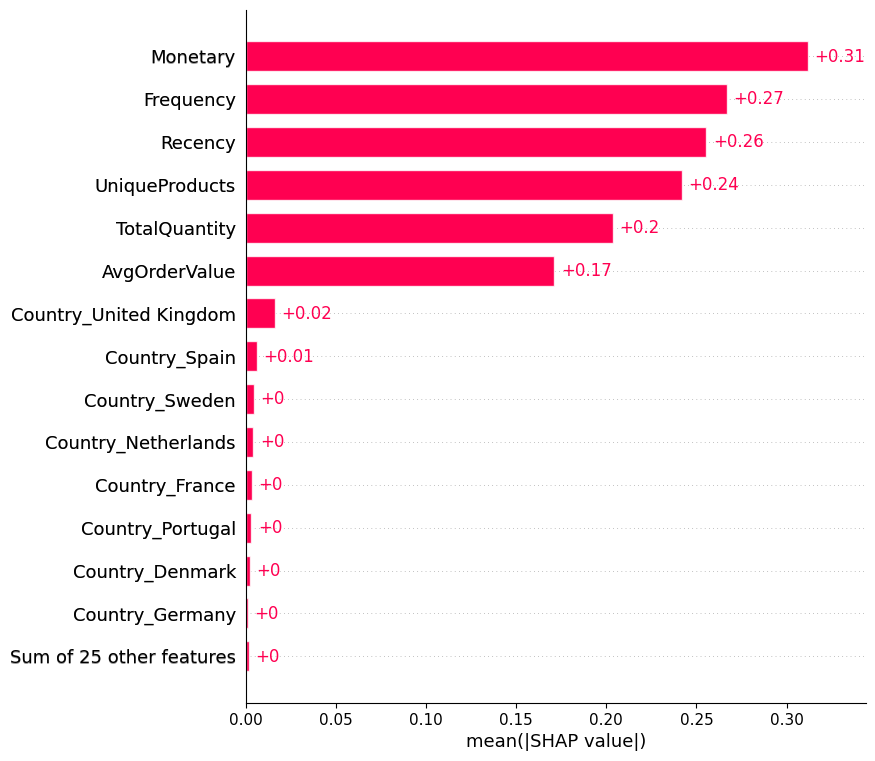

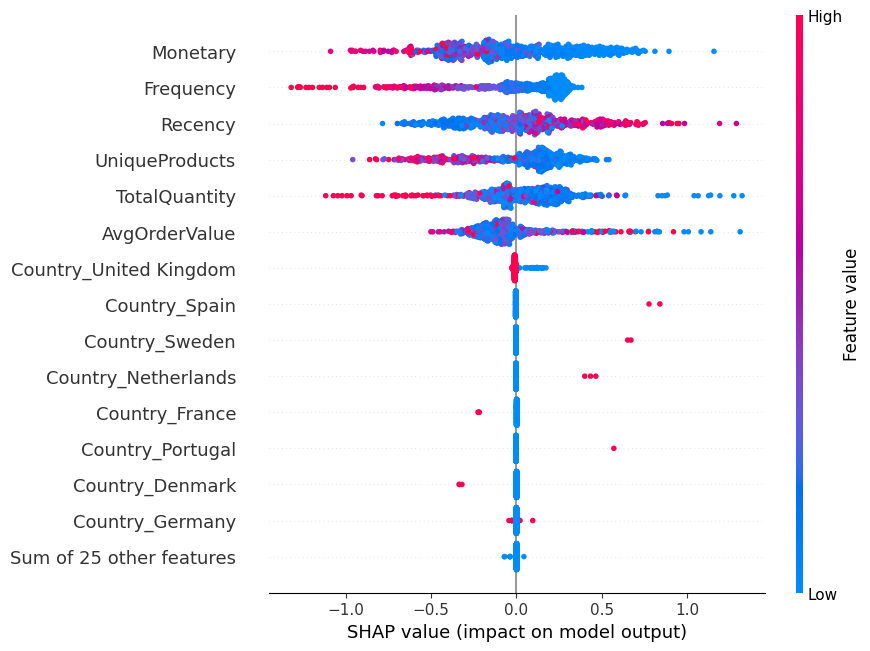

SHAP plots saved successfully.


In [19]:
# Save SHAP plots

import matplotlib.pyplot as plt
import shap
import os

# Global feature importance
shap.plots.bar(shap_values, max_display=15, show=False)
plt.savefig(
    os.path.join(model_dir, "shap_feature_importance.png"),
    bbox_inches="tight",
    dpi=300
)
plt.show()
plt.close()

# SHAP summary plot
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.savefig(
    os.path.join(model_dir, "shap_summary_plot.png"),
    bbox_inches="tight",
    dpi=300
)
plt.show()
plt.close()

print("SHAP plots saved successfully.")

In [20]:
# Save the model evaluation report

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
import pandas as pd

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Churn Precision": precision_score(y_test, y_pred, pos_label=1),
    "Churn Recall": recall_score(y_test, y_pred, pos_label=1),
    "Churn F1 Score": f1_score(y_test, y_pred, pos_label=1),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Value"]
)

display(metrics_df.round(4))

metrics_df.to_csv(
    os.path.join(model_dir, "model_evaluation_metrics.csv"),
    index=False
)

print("Evaluation metrics saved.")

,Metric,Value
0,Accuracy,0.6524
1,Churn Precision,0.5878
2,Churn Recall,0.6063
3,Churn F1 Score,0.5969
4,ROC-AUC,0.7101


Evaluation metrics saved.


In [21]:
# Test loading the saved model

loaded_model = joblib.load(model_path)
saved_features = joblib.load(feature_path)

# Ensure the test data uses the saved feature order
X_test_saved = X_test[saved_features]

# Predict using the loaded model
loaded_predictions = loaded_model.predict(X_test_saved)

print("Predictions from loaded model:")
print(loaded_predictions[:10])

print(
    "Predictions match:",
    (loaded_predictions == y_pred).all()
)

Predictions from loaded model:
[0 1 1 0 0 1 0 1 1 0]
Predictions match: True
